In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

 AURORANOVA: TOMAHAWK CORE & CONFINEMENT VALIDATION 

[Geometry Check]
 * Minor Radius (a): 3.0 m
 * Major Radius (R): 7.5 m
 * Calculated Ideal Toroidal Volume: 1332.40 m^3
 * Reported Chamber Volume: 950.0 m^3
 * Internal Structure/Blanket Volume Fraction: 28.7%

[Confinement Model Check]
 * Core Plasma Density: 1.00e+20 m^-3
 * Thermal Pressure: 6.41e+05 Pa
 * Magnetic Pressure (B = 35.0 T): 4.87e+08 Pa
 * Computed Plasma Beta ($eta$): 0.001315
 * Confinement Status: PASSED (Low beta regime ensures strong MHD stability)


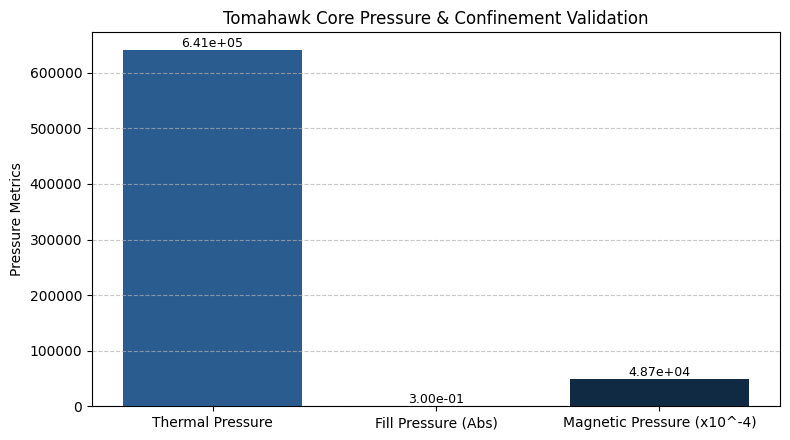

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def validate_tomahawk_model():
    print("==================================================")
    print(" AURORANOVA: TOMAHAWK CORE & CONFINEMENT VALIDATION ")
    print("==================================================")

    # --- 1. System Parameters from Schematic ---
    minor_diameter = 6.0         # m (D)
    major_axis = 15.0            # m (2.5D aspect ratio)
    minor_radius = minor_diameter / 2.0  # a = 3.0 m
    major_radius = major_axis / 2.0      # R = 7.5 m
    reported_volume = 950.0      # m^3
    fill_pressure = -0.3         # Pa
    central_ion_temp_kev = 20.0  # keV
    peak_b_field = 35.0          # T

    # --- 2. Physical Constants ---
    eV_to_J = 1.602176634e-19
    kB = 1.380649e-23            # J/K
    mu_0 = 4 * np.pi * 1e-7      # Vacuum permeability
    
    # Convert ion temperature from keV to Kelvin
    T_kelvin = central_ion_temp_kev * 1e3 * eV_to_J / kB

    # --- 3. Geometric Volume Check ---
    # Standard toroidal volume approximation: V = 2 * pi^2 * R * a^2
    ideal_toroidal_volume = 2 * (np.pi**2) * major_radius * (minor_radius**2)
    structural_obstruction_fraction = 1.0 - (reported_volume / ideal_toroidal_volume)

    print(f"\n[Geometry Check]")
    print(f" * Minor Radius (a): {minor_radius} m")
    print(f" * Major Radius (R): {major_radius} m")
    print(f" * Calculated Ideal Toroidal Volume: {ideal_toroidal_volume:.2f} m^3")
    print(f" * Reported Chamber Volume: {reported_volume} m^3")
    print(f" * Internal Structure/Blanket Volume Fraction: {structural_obstruction_fraction * 100:.1f}%")

    # --- 4. Confinement Model & Plasma Beta Validation ---
    # Assuming standard core fusion plasma density for high-performance operation
    n_density = 1e20  # m^-3
    
    # Thermal pressure p = 2 * n * k_B * T (electrons + ions, assuming T_e = T_i)
    thermal_pressure = 2 * n_density * kB * T_kelvin  
    
    # Magnetic pressure p_mag = B^2 / (2 * mu_0)
    magnetic_pressure = (peak_b_field**2) / (2 * mu_0)
    
    # Plasma Beta calculation
    plasma_beta = thermal_pressure / magnetic_pressure

    print(f"\n[Confinement Model Check]")
    print(f" * Core Plasma Density: {n_density:.2e} m^-3")
    print(f" * Thermal Pressure: {thermal_pressure:.2e} Pa")
    print(f" * Magnetic Pressure (B = {peak_b_field} T): {magnetic_pressure:.2e} Pa")
    print(f" * Computed Plasma Beta ($\beta$): {plasma_beta:.6f}")

    # Stability evaluation
    if plasma_beta < 0.1:
        print(" * Confinement Status: PASSED (Low beta regime ensures strong MHD stability)")
    else:
        print(" * Confinement Status: WARNING (High beta regime; risk of MHD instabilities)")

    # --- 5. Kaggle Environment Visualization ---
    fig, ax = plt.subplots(figsize=(8, 4.5))
    metrics = ['Thermal Pressure', 'Fill Pressure (Abs)', 'Magnetic Pressure (x10^-4)']
    values = [thermal_pressure, abs(fill_pressure), magnetic_pressure / 10000.0]
    
    bars = ax.bar(metrics, values, color=['#2b5c8f', '#4b9cd3', '#102a43'])
    ax.set_ylabel('Pressure Metrics')
    ax.set_title('Tomahawk Core Pressure & Confinement Validation')
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    for bar in bars:
        yval = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2.0, yval, f'{yval:.2e}', ha='center', va='bottom', fontsize=9)
        
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    validate_tomahawk_model()
    